# How Stable Are SHAP Feature Rankings Across Different Training Samples?
**DS5622 Explainable AI · Track 1 · Kaggle Experiment (20/40/60/80/100% × 5)**

**Research question:** Do global SHAP feature rankings become more stable as Random Forest training sample size increases?

**Hypothesis:** Larger training samples yield more consistent global SHAP feature-importance rankings.



## 1. Imports and configuration


In [2]:
import os, json, sys, platform, warnings, importlib.metadata
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
import shap

BASE_SEED = 2026
SUBSAMPLE_SEEDS = [11, 23, 37, 53, 71]
SAMPLE_FRACTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]
N_ESTIMATORS = 100
MIN_SAMPLES_LEAF = 2
SHAP_EVAL_N = 200
TOP_K = 5
RESULTS_DIR = Path('/kaggle/working/shap_stability_20_40_60_80_100') if Path('/kaggle/working').exists() else Path('shap_stability_20_40_60_80_100_results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(BASE_SEED)
print('Python:',sys.version.split()[0], '| scikit-learn:',importlib.metadata.version('scikit-learn'), '| SHAP:', shap.__version__)
print('Outputs:', RESULTS_DIR.resolve())

Python: 3.13.18 | scikit-learn: 1.6.1 | SHAP: 0.54.1
Outputs: /kaggle/working/shap_stability_20_40_60_80_100


## 2. Load the real UCI dataset


In [5]:

import kagglehub
import pandas as pd
from pathlib import Path

# Download dataset
path = kagglehub.dataset_download(
    "uciml/default-of-credit-card-clients-dataset"
)

print("Dataset location:", path)

# Find CSV files
csv_files = list(Path(path).rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV dataset found.")

# Select the dataset
DATA_PATH = csv_files[0]

# Load data
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

raw = pd.read_csv(DATA_PATH)
raw.columns = raw.columns.astype(str).str.strip()
print('Dataset:', DATA_PATH)
print('Raw shape:', raw.shape)
display(raw.head(3))

Dataset location: /kaggle/input/datasets/uciml/default-of-credit-card-clients-dataset
Dataset shape: (30000, 25)
Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


Dataset: /kaggle/input/datasets/uciml/default-of-credit-card-clients-dataset/UCI_Credit_Card.csv
Raw shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


## 3. Preprocessing and the fixed holdout set


In [10]:
target_aliases = ['default.payment.next.month', 'default payment next month', 'default_payment_next_month', 'Y']
target = next((col for col in target_aliases if col in raw.columns), None)
if target is None:
    raise ValueError(f'Expected default target not found; available columns: {list(raw.columns)}')
df = raw.copy()
df = df.loc[:, ~df.columns.str.match(r'^Unnamed:')]
y = pd.to_numeric(df[target], errors='raise').astype(int)
X = df.drop(columns=[target, 'ID', 'id'], errors='ignore')
X = X.apply(pd.to_numeric, errors='coerce')
if y.nunique() != 2 or not set(y.unique()).issubset({0,1}):
    raise ValueError('Target should be binary with labels 0 (non-default) and 1 (default).')
if len(X.columns) != 23:
    raise ValueError(f'Expected 23 predictor columns; got {len(X.columns)}. Check the dataset and ID column.')
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=BASE_SEED)
medians = X_train_raw.median().fillna(0)
X_train = X_train_raw.fillna(medians).astype(float)
X_test = X_test_raw.fillna(medians).astype(float)
if len(X_test) <= SHAP_EVAL_N:
    X_explain = X_test.copy()
else:
    X_explain, _, _, _ = train_test_split(X_test, y_test, train_size=SHAP_EVAL_N, random_state=BASE_SEED, stratify=y_test)
assert not X_train.index.intersection(X_test.index).size
print(f'Train={len(X_train)}, test={len(X_test)}, fixed SHAP observations={len(X_explain)}')
print('Default prevalence:',round(y.mean(),4))

Train=24000, test=6000, fixed SHAP observations=200
Default prevalence: 0.2212


## 4. Model and SHAP utilities


In [12]:
FEATURE_NAMES = list(X_train.columns)

def fit_model(X_fit, y_fit):
    model = RandomForestClassifier(n_estimators=N_ESTIMATORS, min_samples_leaf=MIN_SAMPLES_LEAF,
                                   random_state=BASE_SEED, n_jobs=-1)
    return model.fit(X_fit, y_fit)

def positive_class_shap(model, features):
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(features, check_additivity=False)
    if isinstance(sv, list):
        arr = np.asarray(sv[1])
    else:
        arr = np.asarray(getattr(sv, 'values', sv))
        if arr.ndim == 3:
            arr = arr[:, :, 1]
    if arr.shape != (len(features), len(FEATURE_NAMES)):
        raise ValueError(f'Unexpected positive-class SHAP shape {arr.shape}')
    if not np.isfinite(arr).all():
        raise ValueError('SHAP returned non-finite values')
    return arr

def get_importance(model):
    shap_array = positive_class_shap(model, X_explain)
    return np.abs(shap_array).mean(axis=0), shap_array

def rank_features(importance):
    # Stable deterministic tie rule: alphabetical feature order, secondary to importance.
    order = np.lexsort((np.array(FEATURE_NAMES), -np.asarray(importance)))
    ranks = np.empty(len(order), dtype=int)
    ranks[order] = np.arange(1, len(order)+1)
    return ranks, order

def overlap(order_a, order_b, k):
    return len(set(order_a[:k]).intersection(order_b[:k])) / k

## 5. Train the baseline and the 20/40/60/80/100% × 5 experiment



In [13]:
models = {}
importances = {}
orders = {}
metrics = []

def evaluate_and_store(name, frac, seed, X_fit, y_fit):
    model = fit_model(X_fit, y_fit)
    roc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
    imp, _ = get_importance(model)
    _, order = rank_features(imp)
    models[name] = model
    importances[name] = imp
    orders[name] = order
    metrics.append({'model':name, 'fraction':frac, 'seed':seed,
                    'n_train':len(X_fit), 'roc_auc':roc,
                    'run_type':'baseline' if name == 'baseline_100%' else 'independent_subsample'})
    print(f'{name:18s} rows={len(X_fit):5d}  ROC-AUC={roc:.4f}')

# Fit the baseline only once.
evaluate_and_store('baseline_100%', 1.0, BASE_SEED, X_train, y_train)

for fraction in SAMPLE_FRACTIONS:
    for seed in SUBSAMPLE_SEEDS:
        name = f'{int(round(fraction*100))}pct_seed{seed}'
        if fraction == 1.0:
            # No new subset is possible with 100% training data.
            # Since both dataset and RF random_state are fixed, a new fit would be identical.
            models[name] = models['baseline_100%']
            importances[name] = importances['baseline_100%'].copy()
            orders[name] = orders['baseline_100%'].copy()
            metrics.append({'model':name, 'fraction':fraction, 'seed':seed,
                            'n_train':len(X_train),
                            'roc_auc':metrics[0]['roc_auc'],
                            'run_type':'identical_100pct_control_reuses_baseline'})
            print(f'{name:18s} rows={len(X_train):5d}  reproducibility control (baseline reused)')
        else:
            X_sub, _, y_sub, _ = train_test_split(
                X_train, y_train, train_size=fraction,
                stratify=y_train, random_state=seed
            )
            evaluate_and_store(name, fraction, seed, X_sub, y_sub)

model_results = pd.DataFrame(metrics)
display(model_results)
assert len(models) == 26  # 25 requested settings + reference baseline
assert len(model_results) == 26
assert model_results.query('fraction == 1.0').roc_auc.nunique() == 1
print('Actual trained fits: 21 (20 subsamples + 1 full-data reference).')


baseline_100%      rows=24000  ROC-AUC=0.7745
20pct_seed11       rows= 4800  ROC-AUC=0.7699
20pct_seed23       rows= 4800  ROC-AUC=0.7611
20pct_seed37       rows= 4800  ROC-AUC=0.7722
20pct_seed53       rows= 4800  ROC-AUC=0.7517
20pct_seed71       rows= 4800  ROC-AUC=0.7692
40pct_seed11       rows= 9600  ROC-AUC=0.7766
40pct_seed23       rows= 9600  ROC-AUC=0.7650
40pct_seed37       rows= 9600  ROC-AUC=0.7721
40pct_seed53       rows= 9600  ROC-AUC=0.7650
40pct_seed71       rows= 9600  ROC-AUC=0.7708
60pct_seed11       rows=14400  ROC-AUC=0.7739
60pct_seed23       rows=14400  ROC-AUC=0.7735
60pct_seed37       rows=14400  ROC-AUC=0.7702
60pct_seed53       rows=14400  ROC-AUC=0.7703
60pct_seed71       rows=14400  ROC-AUC=0.7707
80pct_seed11       rows=19200  ROC-AUC=0.7732
80pct_seed23       rows=19200  ROC-AUC=0.7733
80pct_seed37       rows=19200  ROC-AUC=0.7741
80pct_seed53       rows=19200  ROC-AUC=0.7693
80pct_seed71       rows=19200  ROC-AUC=0.7717
100pct_seed11      rows=24000  rep

,model,fraction,seed,n_train,roc_auc,run_type
0,baseline_100%,1.0,2026,24000,0.774541,baseline
1,20pct_seed11,0.2,11,4800,0.769868,independent_subsample
2,20pct_seed23,0.2,23,4800,0.761106,independent_subsample
3,20pct_seed37,0.2,37,4800,0.772173,independent_subsample
4,20pct_seed53,0.2,53,4800,0.751736,independent_subsample
5,20pct_seed71,0.2,71,4800,0.769235,independent_subsample
6,40pct_seed11,0.4,11,9600,0.776627,independent_subsample
7,40pct_seed23,0.4,23,9600,0.764995,independent_subsample
8,40pct_seed37,0.4,37,9600,0.772141,independent_subsample
9,40pct_seed53,0.4,53,9600,0.764954,independent_subsample


Actual trained fits: 21 (20 subsamples + 1 full-data reference).


## 6. Pairwise ranking stability



In [14]:
pairs = []
for fraction in SAMPLE_FRACTIONS:
    names = [f'{int(round(fraction*100))}pct_seed{seed}' for seed in SUBSAMPLE_SEEDS]
    for a,b in combinations(names,2):
        a_rank, _ = rank_features(importances[a])
        b_rank, _ = rank_features(importances[b])
        corr = float(spearmanr(a_rank,b_rank).statistic)
        auc_a = float(model_results.set_index('model').loc[a,'roc_auc'])
        auc_b = float(model_results.set_index('model').loc[b,'roc_auc'])
        pairs.append({'fraction':fraction, 'model_a':a, 'model_b':b,
                      'spearman':corr,
                      'top3_overlap':overlap(orders[a],orders[b],3),
                      'top5_overlap':overlap(orders[a],orders[b],5),
                      'auc_mean':(auc_a+auc_b)/2,
                      'auc_difference':abs(auc_a-auc_b)})
pair_results = pd.DataFrame(pairs)
summary = pair_results.groupby('fraction',as_index=False).agg(
    spearman_mean=('spearman','mean'), spearman_min=('spearman','min'),
    spearman_max=('spearman','max'),spearman_sd=('spearman','std'),
    top3_mean=('top3_overlap','mean'),top5_mean=('top5_overlap','mean'),
    auc_mean=('auc_mean','mean'))
print('Pairwise comparisons:');display(pair_results.round(4))
print('Descriptive summary:');display(summary.round(4))
assert len(pair_results) == len(SAMPLE_FRACTIONS) * 10
control = pair_results.loc[np.isclose(pair_results['fraction'], 1.0)]
assert np.allclose(control['spearman'], 1.0)
assert np.allclose(control['top3_overlap'], 1.0)
assert np.allclose(control['top5_overlap'], 1.0)
print('100% reproducibility control verified (all comparison metrics = 1).')


Pairwise comparisons:


,fraction,model_a,model_b,spearman,top3_overlap,top5_overlap,auc_mean,auc_difference
0,0.2,20pct_seed11,20pct_seed23,0.8538,1.0,0.6,0.7655,0.0088
1,0.2,20pct_seed11,20pct_seed37,0.8933,1.0,0.8,0.7710,0.0023
2,0.2,20pct_seed11,20pct_seed53,0.9170,1.0,0.8,0.7608,0.0181
3,0.2,20pct_seed11,20pct_seed71,0.9595,1.0,0.8,0.7696,0.0006
4,0.2,20pct_seed23,20pct_seed37,0.8202,1.0,0.6,0.7666,0.0111
5,0.2,20pct_seed23,20pct_seed53,0.8182,1.0,0.6,0.7564,0.0094
6,0.2,20pct_seed23,20pct_seed71,0.8676,1.0,0.6,0.7652,0.0081
7,0.2,20pct_seed37,20pct_seed53,0.8231,1.0,0.6,0.7620,0.0204
8,0.2,20pct_seed37,20pct_seed71,0.9101,1.0,0.6,0.7707,0.0029
9,0.2,20pct_seed53,20pct_seed71,0.9091,1.0,0.8,0.7605,0.0175


Descriptive summary:


,fraction,spearman_mean,spearman_min,spearman_max,spearman_sd,top3_mean,top5_mean,auc_mean
0,0.2,0.8772,0.8182,0.9595,0.0483,1.0,0.68,0.7648
1,0.4,0.9476,0.9101,0.9733,0.0191,1.0,0.86,0.7699
2,0.6,0.9624,0.9427,0.9822,0.0138,1.0,0.88,0.7717
3,0.8,0.9743,0.9664,0.9872,0.0072,1.0,0.88,0.7723
4,1.0,1.0000,1.0000,1.0000,0.0000,1.0,1.00,0.7745


100% reproducibility control verified (all comparison metrics = 1).


## 7. Plots



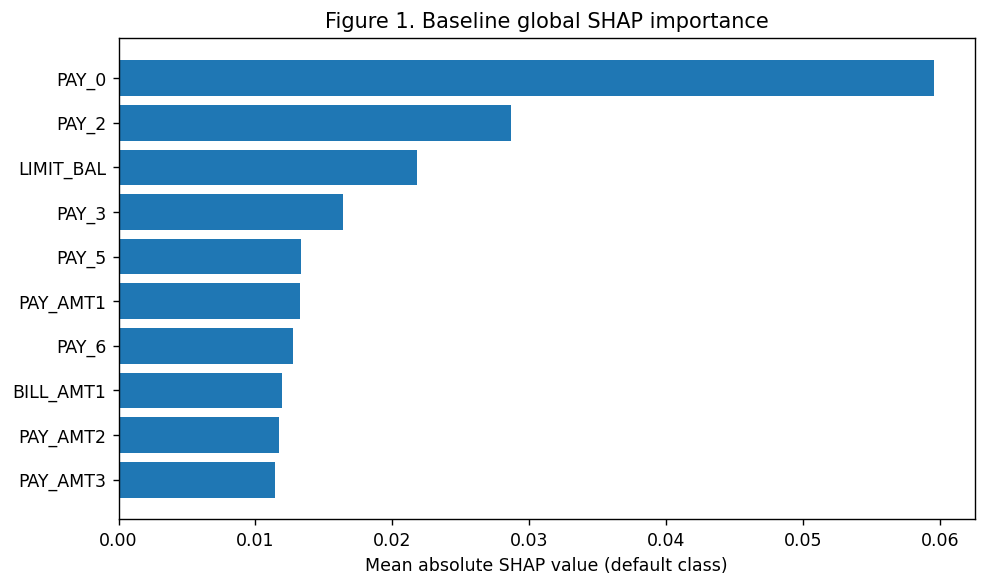

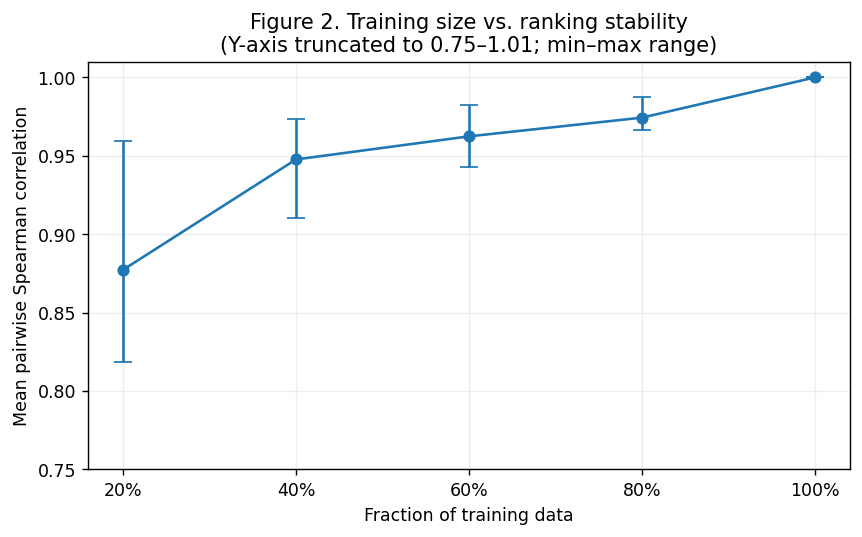

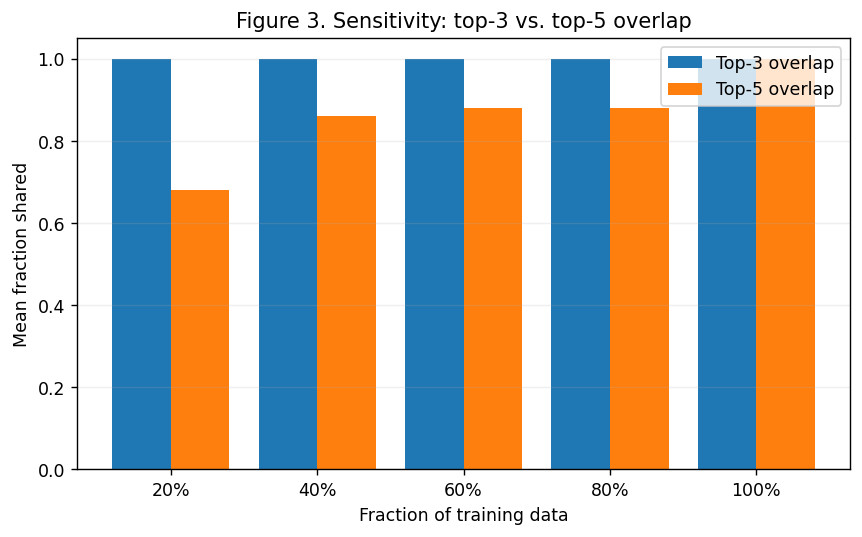

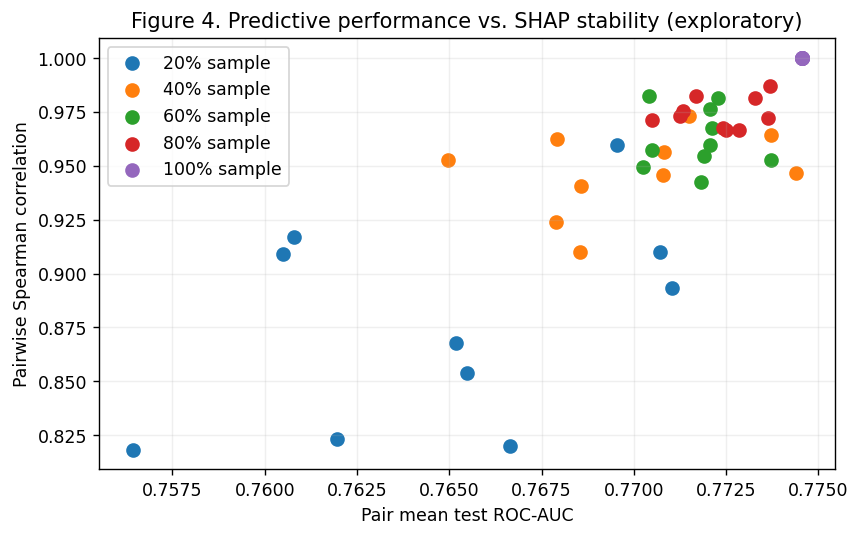

In [15]:
plt.rcParams.update({'figure.dpi':125, 'savefig.dpi':180, 'font.size':10})
def savefig(filename):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/filename, bbox_inches='tight')
    plt.show()

# Fig 1: Reference model's ten most important features
baseline_imp = importances['baseline_100%']
top10 = np.argsort(baseline_imp)[-10:]
plt.figure(figsize=(8,4.8))
plt.barh(np.array(FEATURE_NAMES)[top10], baseline_imp[top10])
plt.xlabel('Mean absolute SHAP value (default class)')
plt.title('Figure 1. Baseline global SHAP importance')
savefig('figure_1_baseline_shap.png')

# Fig 2: Spearman stability, with minimum/maximum range across ten pairs per size
x = (summary['fraction']*100).to_numpy()
yv = summary['spearman_mean'].to_numpy()
err = np.vstack([yv-summary['spearman_min'].to_numpy(),summary['spearman_max'].to_numpy()-yv])
plt.figure(figsize=(7,4.4))
plt.errorbar(x,yv,yerr=err,marker='o',capsize=5,linewidth=1.5)
plt.xticks(x, [f'{v:.0f}%' for v in x])
# Keep the zoomed axis but never cut off observed minimum–maximum values.
min_spearman = float(summary['spearman_min'].min())
y_lower = min(0.80, max(-1.0, np.floor((min_spearman - 0.025) * 20) / 20))
plt.ylim(y_lower, 1.01)
plt.xlabel('Fraction of training data');plt.ylabel('Mean pairwise Spearman correlation')
plt.title(f'Figure 2. Training size vs. ranking stability\n(Y-axis truncated to {y_lower:.2f}–1.01; min–max range)')
plt.grid(alpha=.2)
savefig('figure_2_size_vs_spearman.png')

# Fig 3: Top-k sensitivity
width=8
plt.figure(figsize=(7,4.4))
plt.bar(x-width/2, summary['top3_mean'], width=width, label='Top-3 overlap')
plt.bar(x+width/2, summary['top5_mean'], width=width, label='Top-5 overlap')
plt.xticks(x, [f'{v:.0f}%' for v in x]);plt.ylim(0,1.05)
plt.xlabel('Fraction of training data');plt.ylabel('Mean fraction shared')
plt.title('Figure 3. Sensitivity: top-3 vs. top-5 overlap')
plt.legend();plt.grid(axis='y',alpha=.2)
savefig('figure_3_topk_sensitivity.png')

# Fig 4: AUC vs. explanation stability for 50 non-independent pairs (100% is a control)
plt.figure(figsize=(7,4.4))
for f,group in pair_results.groupby('fraction'):
    plt.scatter(group['auc_mean'],group['spearman'],label=f'{int(f*100)}% sample',s=55)
plt.xlabel('Pair mean test ROC-AUC');plt.ylabel('Pairwise Spearman correlation')
plt.title('Figure 4. Predictive performance vs. SHAP stability (exploratory)')
plt.legend();plt.grid(alpha=.2)
savefig('figure_4_auc_vs_stability.png')

## 8. Inspect the least-stable comparison and test the hypothesis


In [16]:
worst = pair_results.sort_values('spearman').iloc[0]
a,b = worst['model_a'], worst['model_b']
print('Least stable pair:', a, 'vs', b)
print('Spearman:',round(float(worst['spearman']),4),'| Top-5 overlap:',round(float(worst['top5_overlap']),4))
print('Model A top-5:', [FEATURE_NAMES[i] for i in orders[a][:5]])
print('Model B top-5:', [FEATURE_NAMES[i] for i in orders[b][:5]])
print('AUC difference:',round(float(worst['auc_difference']),5))
means = summary.sort_values('fraction')['spearman_mean'].to_numpy()
if np.all(np.diff(means) >= 0):
    print('OBSERVATION: Mean rank correlation is nondecreasing across the five tested sample sizes.')
else:
    print('OBSERVATION: Mean rank correlation is NOT monotonically nondecreasing across the tested sample sizes.')
print('CAUTION: This observation is based on five labeled repetitions per size (100% is identical control) and is not a significance test.')

Least stable pair: 20pct_seed23 vs 20pct_seed53
Spearman: 0.8182 | Top-5 overlap: 0.6
Model A top-5: ['PAY_0', 'PAY_2', 'LIMIT_BAL', 'PAY_AMT3', 'PAY_4']
Model B top-5: ['PAY_0', 'LIMIT_BAL', 'PAY_2', 'PAY_5', 'PAY_3']
AUC difference: 0.00937
OBSERVATION: Mean rank correlation is nondecreasing across the five tested sample sizes.
CAUTION: This observation is based on five labeled repetitions per size (100% is identical control) and is not a significance test.


## 8A. Verify SHAP additivity (baseline model)



In [17]:
# Technical validation: SHAP additivity for class 1 (default)
import json
check_model = models["baseline_100%"]
check_data = X_explain.iloc[:20].copy()
check_explainer = shap.TreeExplainer(check_model)
check_sv = check_explainer.shap_values(check_data, check_additivity=True)

if isinstance(check_sv, list):
    check_values = np.asarray(check_sv[1], dtype=float)
else:
    check_values = np.asarray(getattr(check_sv, "values", check_sv), dtype=float)
    if check_values.ndim == 3:
        check_values = check_values[:, :, 1]

expected_values = np.asarray(check_explainer.expected_value, dtype=float).reshape(-1)
if expected_values.size != 2:
    raise ValueError(f"Expected two binary-class base values; got {expected_values}")
base_value = float(expected_values[1])

if check_values.shape != (len(check_data), len(FEATURE_NAMES)):
    raise ValueError(f"Unexpected positive-class SHAP shape: {check_values.shape}")

actual_probability = check_model.predict_proba(check_data)[:, 1]
reconstructed_probability = base_value + check_values.sum(axis=1)
absolute_error = np.abs(actual_probability - reconstructed_probability)

verification = pd.DataFrame({
    "actual_default_probability": actual_probability,
    "shap_reconstructed_probability": reconstructed_probability,
    "absolute_error": absolute_error
}, index=check_data.index)
display(verification.round(9))
max_error = float(absolute_error.max())
passed = bool(np.allclose(actual_probability, reconstructed_probability, rtol=0, atol=1e-5))

verification.to_csv(RESULTS_DIR / "shap_additivity_verification.csv", index_label="test_row_index")
(RESULTS_DIR / "shap_additivity_summary.json").write_text(json.dumps({
    "model": "baseline_100%",
    "class": 1,
    "observations_checked": len(check_data),
    "base_value": base_value,
    "maximum_absolute_error": max_error,
    "absolute_tolerance": 1e-5,
    "passed": passed
}, indent=2))

print(f"Maximum absolute error: {max_error:.12g}")
print("PASS: SHAP additivity verified." if passed else "CHECK REQUIRED: SHAP reconstruction does not match.")
assert passed, "SHAP additivity validation failed."


,actual_default_probability,shap_reconstructed_probability,absolute_error
1133,0.665262,0.665262,0.0
28801,0.028333,0.028333,0.0
5202,0.600333,0.600333,0.0
28415,0.033333,0.033333,0.0
21170,0.154500,0.154500,0.0
2714,0.767833,0.767833,0.0
2020,0.084167,0.084167,0.0
7751,0.448000,0.448000,0.0
14657,0.466061,0.466061,0.0
11525,0.109167,0.109167,0.0


Maximum absolute error: 5.03819208575e-13
PASS: SHAP additivity verified.


## 9. Export results and reproducibility information

In [18]:
model_results.to_csv(RESULTS_DIR/'model_roc_auc.csv',index=False)
pair_results.to_csv(RESULTS_DIR/'pairwise_stability.csv',index=False)
summary.to_csv(RESULTS_DIR/'stability_summary.csv',index=False)
pd.DataFrame({'feature':FEATURE_NAMES,'baseline_mean_abs_shap':baseline_imp}).sort_values('baseline_mean_abs_shap',ascending=False).to_csv(RESULTS_DIR/'baseline_feature_importance.csv',index=False)
config = {'dataset':str(DATA_PATH),'train_test_split':0.2,'split_seed':BASE_SEED,
          'design_note':'Five seeded subsamples at 20-80%, identical 100% controls reuse fitted baseline', 'fractions':SAMPLE_FRACTIONS,'subsample_seeds':SUBSAMPLE_SEEDS,
          'n_estimators':N_ESTIMATORS,'min_samples_leaf':MIN_SAMPLES_LEAF,
          'shap_eval_n':len(X_explain),'features':FEATURE_NAMES,
          'package_versions':{pkg:importlib.metadata.version(pkg) for pkg in ['numpy','pandas','scikit-learn','scipy','shap','matplotlib']},
          'python':sys.version.split()[0]}
(RESULTS_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2))
lines = ['# Experimental results (automatically generated)',
         'The results below come from the dataset actually loaded by the notebook. Values are descriptive.',
         '', '## Reference baseline',
         f"ROC-AUC = {model_results.loc[model_results.model=='baseline_100%','roc_auc'].iloc[0]:.4f}",
         '', '## Stability by training sample size']
for _,r in summary.iterrows():
    lines.append(f"- {int(r['fraction']*100)}%: Spearman mean={r['spearman_mean']:.4f} (range {r['spearman_min']:.4f} to {r['spearman_max']:.4f}); top-3={r['top3_mean']:.3f}, top-5={r['top5_mean']:.3f}.")
lines += ['',f'Least-stable pair: {a} / {b}, Spearman={worst.spearman:.4f}.',
          '', '## Required interpretation',
          'Discuss trend, spread, unexpected cases, model AUC, correlated predictors, small repetition count, model/dataset specificity, and SHAP assumptions.',
          'The 50 within-size pairwise comparisons are not independent observations; 100% controls are identical by design.',
          'Only one fixed 200-observation (or configured-size) explanation sample was used.',
          '20 distinct subset models plus one baseline were trained; 100% control rows reuse baseline results.',
          'LLM/code assistance must be disclosed and outputs verified by execution and manual checks.']
(RESULTS_DIR/'results_summary.md').write_text('\n'.join(lines)+'\n')
print('Saved files:')
for item in sorted(RESULTS_DIR.iterdir()):
    print(' -', item.name)
print('\nRun completed; check the tables and figures before writing conclusions.')

Saved files:
 - baseline_feature_importance.csv
 - experiment_config.json
 - figure_1_baseline_shap.png
 - figure_2_size_vs_spearman.png
 - figure_3_topk_sensitivity.png
 - figure_4_auc_vs_stability.png
 - model_roc_auc.csv
 - pairwise_stability.csv
 - results_summary.md
 - shap_additivity_summary.json
 - shap_additivity_verification.csv
 - stability_summary.csv

Run completed; check the tables and figures before writing conclusions.
